In [1]:
%% MIT 18.03 Lecture 35: Linear Phase Portraits & Trace-Determinant Plane
% Description: Visualizes the Trace-Determinant stability/topology map and marginal cases:
%              1) Trace-Determinant Plane with Critical Parabola det(A) = tr(A)^2 / 4,
%                 mapping benchmark systems from Lectures 32-35.
%              2) Saddle Phase Portrait from Sec [2]: A = [1, 1; 0, -2] (v1=[1;0], v2=[-1;3]).
%              3) Marginal "Comb" Portrait from Sec [4]: det(A) = 0, tr(A) < 0 (Neutrally Stable).
%
% % Required Toolboxes:
% %   - Control System Toolbox (ss, initial, pole).
%
% % MBD Concept Mapping: Connects the Trace-Determinant plane directly to 2nd-order Routh-Hurwitz
% %                      stability (tr < 0, det > 0) and damping ratio regimes (parabola zeta = 1).


clear; clc; close all;


%% =========================================================================
%% Part 1: Trace-Determinant Plane & Benchmark Systems Mapping
%% =========================================================================
% Define benchmark matrices from Lectures 32-35:
% 1. Rabbits (Lec 32/35): [0.3, 0.1; 0.2, 0.4] -> tr = 0.7, det = 0.1 (Unstable Node / Source)
% 2. Romeo & Juliet (Lec 32): [0, 1; -17/16, 0.5] -> tr = 0.5, det = 1.0625 (Unstable Spiral)
% 3. Saddle (Lec 35 Sec [2]): [1, 1; 0, -2] -> tr = -1.0, det = -2.0 (Saddle Point)
% 4. Defective Sink (Lec 34/35): [-2, 1; -1, 0] -> tr = -2.0, det = 1.0 (On Critical Parabola)
% 5. Damped Oscillator: [0, 1; -2, -1] -> tr = -1.0, det = 2.0 (Stable Spiral Sink)
% 6. Marginal Comb (Lec 35 Sec [4]): [-1, 1; 0, 0] -> tr = -1.0, det = 0.0 (Neutrally Stable Comb)


sys_benchmarks = {
    'Rabbits (Source Node)',      [0.3, 0.1; 0.2, 0.4];
    'Romeo & Juliet (Spiral)',    [0, 1; -17/16, 0.5];
    'Lec 35 Saddle',              [1, 1; 0, -2];
    'Defective Sink (Parabola)',  [-2, 1; -1, 0];
    'Asymptotically Stable Sink', [0, 1; -2, -1];
    'Neutrally Stable Comb',      [-1, 1; 0, 0]
};


fprintf('=== MIT 18.03 Lecture 35 Trace-Determinant Diagnostics ===\n');

=== MIT 18.03 Lecture 35 Trace-Determinant Diagnostics ===

In [2]:
for k = 1:size(sys_benchmarks, 1)
    name_str = sys_benchmarks{k, 1};
    A_k = sys_benchmarks{k, 2};
    p_k = pole(ss(A_k, zeros(2,1), eye(2), zeros(2,1)));
    fprintf('%-28s | tr = %+5.2f | det = %+6.3f | Poles: %+.2f%+.2fi, %+.2f%+.2fi\n', ...
            name_str, trace(A_k), det(A_k), real(p_k(1)), imag(p_k(1)), real(p_k(2)), imag(p_k(2)));
end

Rabbits (Source Node)        | tr = +0.70 | det = +0.100 | Poles: +0.20+0.00i, +0.50+0.00i
Romeo & Juliet (Spiral)      | tr = +0.50 | det = +1.062 | Poles: +0.25+1.00i, +0.25-1.00i
Lec 35 Saddle                | tr = -1.00 | det = -2.000 | Poles: +1.00+0.00i, -2.00+0.00i
Defective Sink (Parabola)    | tr = -2.00 | det = +1.000 | Poles: -1.00+0.00i, -1.00+0.00i
Asymptotically Stable Sink   | tr = -1.00 | det = +2.000 | Poles: -0.50+1.32i, -0.50-1.32i
Neutrally Stable Comb        | tr = -1.00 | det = -0.000 | Poles: -1.00+0.00i, +0.00+0.00i

In [3]:
fprintf('==========================================================\n\n');


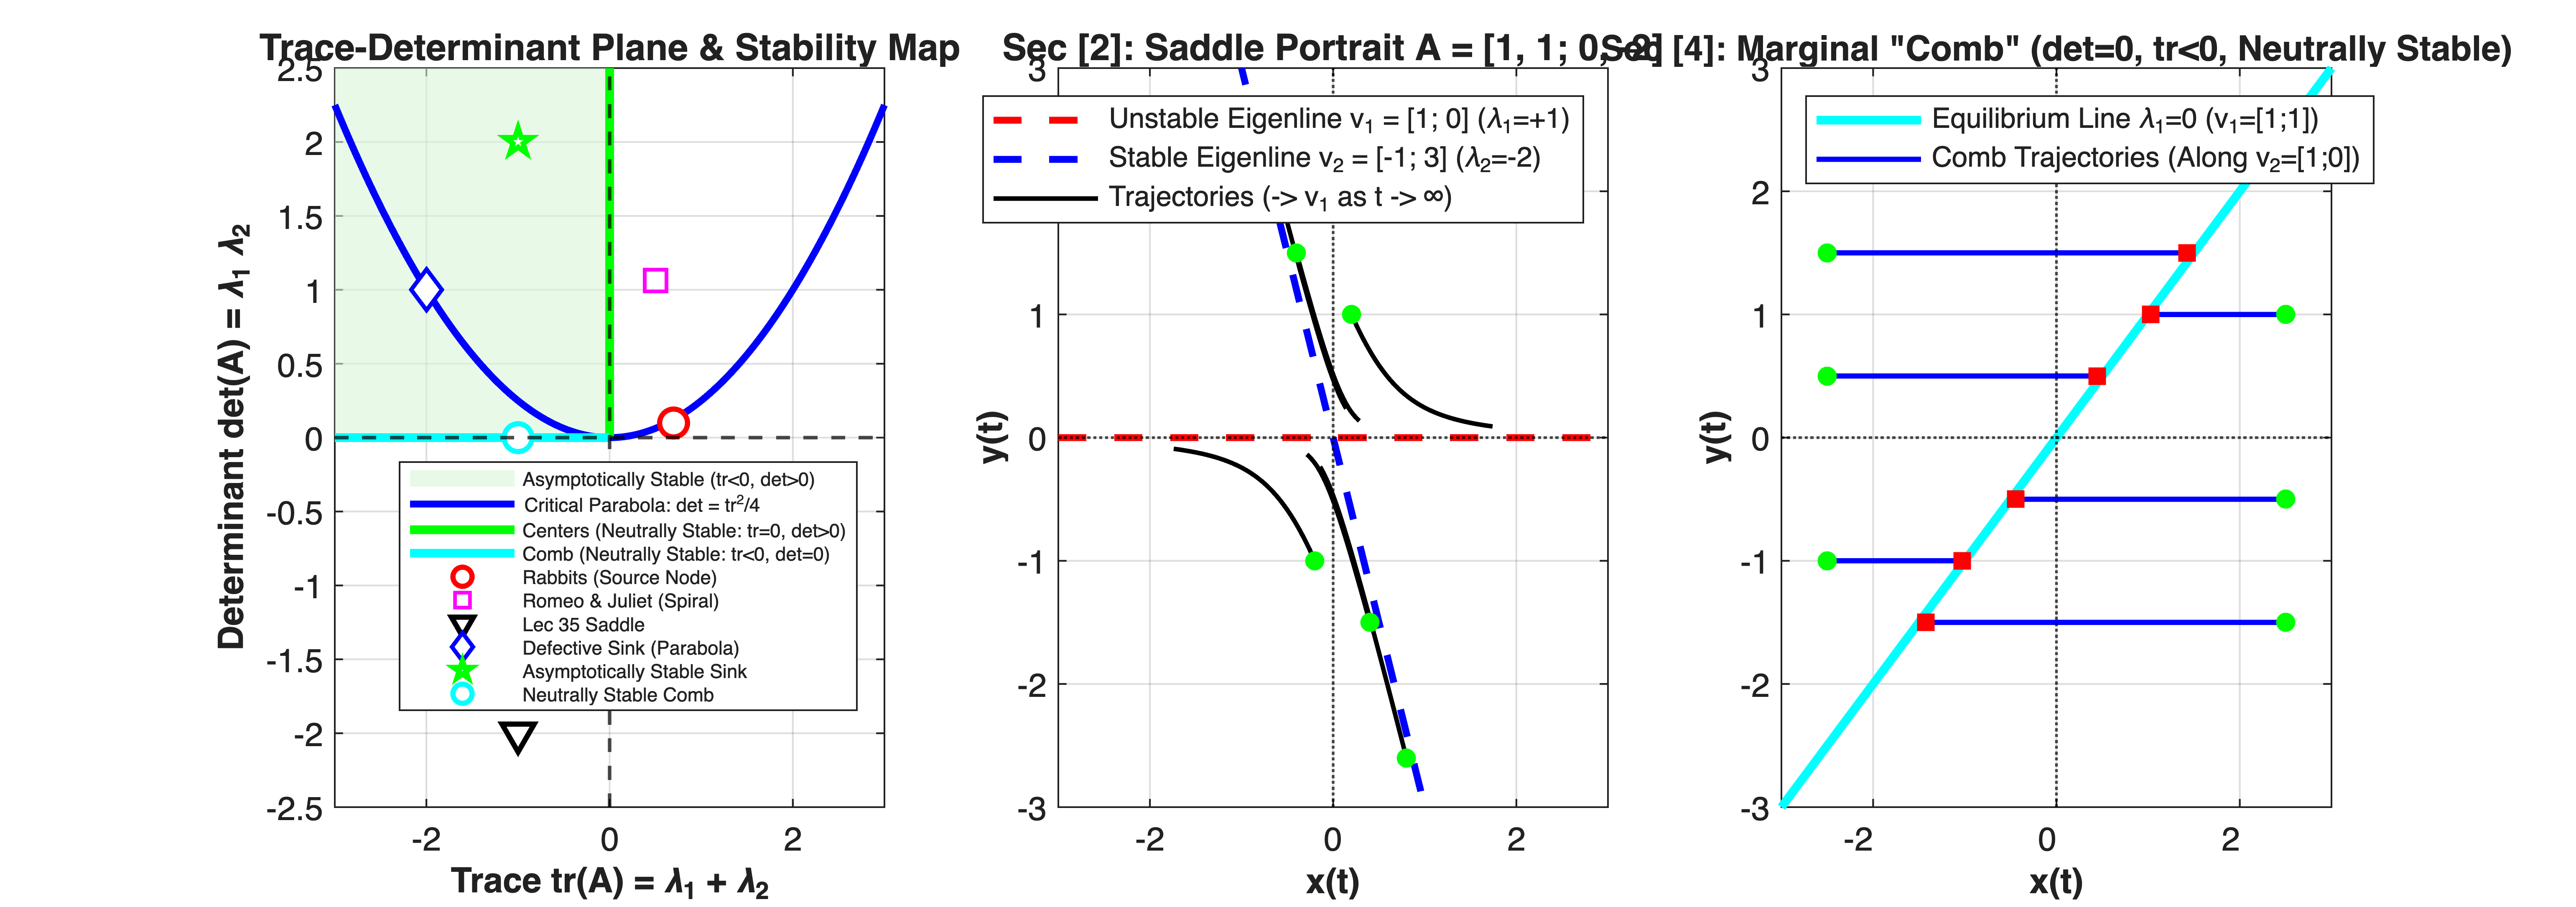

In [4]:


figure('Color', [1 1 1], 'Position', [60, 60, 1280, 450]);


% Subplot 1: The Trace-Determinant Plane
subplot(1, 3, 1);
hold on; grid on; box on;


% Shade Asymptotically Stable Region (Upper-Left Quadrant: tr < 0, det > 0)
patch([-3, 0, 0, -3], [0, 0, 2.5, 2.5], [0.85 0.96 0.85], ...
      'EdgeColor', 'none', 'FaceAlpha', 0.6, 'DisplayName', 'Asymptotically Stable (tr<0, det>0)');


% Plot Critical Parabola: det = tr^2 / 4
tr_vec = linspace(-3, 3, 300);
det_parab = (tr_vec.^2) / 4;
plot(tr_vec, det_parab, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Critical Parabola: det = tr^2/4');


% Highlight Neutral Stability rays (Centers: tr=0, det>0; Comb: tr<0, det=0)
plot([0, 0], [0, 2.5], 'g-', 'LineWidth', 2.5, 'DisplayName', 'Centers (Neutrally Stable: tr=0, det>0)');
plot([-3, 0], [0, 0], 'c-', 'LineWidth', 2.5, 'DisplayName', 'Comb (Neutrally Stable: tr<0, det=0)');
xline(0, 'k--', 'LineWidth', 1.0, 'HandleVisibility', 'off');
yline(0, 'k--', 'LineWidth', 1.0, 'HandleVisibility', 'off');


% Plot benchmark points
markers = {'ro', 'ms', 'kv', 'bd', 'gp', 'co'};
for k = 1:size(sys_benchmarks, 1)
    A_k = sys_benchmarks{k, 2};
    plot(trace(A_k), det(A_k), markers{k}, 'MarkerFaceColor', 'auto', ...
         'MarkerSize', 8, 'LineWidth', 1.5, 'DisplayName', sys_benchmarks{k, 1});
end


xlabel('Trace tr(A) = \lambda_1 + \lambda_2', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Determinant det(A) = \lambda_1 \lambda_2', 'FontSize', 10, 'FontWeight', 'bold');
title('Trace-Determinant Plane & Stability Map', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'southeast', 'FontSize', 5.5);
xlim([-3, 3]); ylim([-2.5, 2.5]);


%% =========================================================================
%% Part 2: Saddle Point A = [1, 1; 0, -2] (Lecture Section [2])
%% =========================================================================
A_saddle = [1,  1;
            0, -2];
sys_saddle = ss(A_saddle, zeros(2,1), eye(2), zeros(2,1));
v1_sad = [1; 0];  % lambda_1 = +1 (Unstable ray)
v2_sad = [-1; 3]; % lambda_2 = -2 (Stable ray)


subplot(1, 3, 2);
hold on; grid on; box on;
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


s_ray = linspace(-3, 3, 100);
plot(s_ray * v1_sad(1), s_ray * v1_sad(2), 'r--', 'LineWidth', 2.0, ...
     'DisplayName', 'Unstable Eigenline v_1 = [1; 0] (\lambda_1=+1)');
plot(s_ray * v2_sad(1), s_ray * v2_sad(2), 'b--', 'LineWidth', 2.0, ...
     'DisplayName', 'Stable Eigenline v_2 = [-1; 3] (\lambda_2=-2)');


t_sad = linspace(0, 1.2, 200);
ic_sad = [-0.8, 2.6;  -0.4, 1.5;  0.8, -2.6;  0.4, -1.5;  0.2, 1.0;  -0.2, -1.0]';
for k = 1:size(ic_sad, 2)
    [u_tr, ~] = initial(sys_saddle, ic_sad(:, k), t_sad);
    plot(u_tr(:, 1), u_tr(:, 2), 'k-', 'LineWidth', 1.3, 'HandleVisibility', 'off');
    plot(ic_sad(1, k), ic_sad(2, k), 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 5, 'HandleVisibility', 'off');
end
plot(NaN, NaN, 'k-', 'LineWidth', 1.3, 'DisplayName', 'Trajectories (-> v_1 as t -> \infty)');


xlabel('x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [2]: Saddle Portrait A = [1, 1; 0, -2]', 'FontSize', 10.5, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8);
xlim([-3, 3]); ylim([-3, 3]);


%% =========================================================================
%% Part 3: Marginal "Comb" Portrait (det(A) = 0, tr(A) < 0, Section [4])
%% =========================================================================
% Matrix A_comb = [-1, 1; 0, 0] -> lambda_1 = 0 (v1 = [1; 1]), lambda_2 = -1 (v2 = [1; 0])
A_comb = [-1, 1;
           0, 0];
sys_comb = ss(A_comb, zeros(2,1), eye(2), zeros(2,1));


subplot(1, 3, 3);
hold on; grid on; box on;
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


% Line of equilibrium points (lambda_1 = 0 -> v1 = [1; 1])
plot(s_ray, s_ray, 'c-', 'LineWidth', 2.5, 'DisplayName', 'Equilibrium Line \lambda_1=0 (v_1=[1;1])');


% Parallel decaying trajectories along v2 = [1; 0] (horizontal teeth of the comb)
t_comb = linspace(0, 4.0, 200);
ic_comb = [-2.5, 1.5;  -2.5, 0.5;  -2.5, -1.0;  2.5, 1.0;  2.5, -0.5;  2.5, -1.5]';
for k = 1:size(ic_comb, 2)
    [u_c, ~] = initial(sys_comb, ic_comb(:, k), t_comb);
    plot(u_c(:, 1), u_c(:, 2), 'b-', 'LineWidth', 1.5, 'HandleVisibility', 'off');
    plot(ic_comb(1, k), ic_comb(2, k), 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 5, 'HandleVisibility', 'off');
    plot(u_c(end, 1), u_c(end, 2), 'rs', 'MarkerFaceColor', 'r', 'MarkerSize', 6, 'HandleVisibility', 'off');
end
plot(NaN, NaN, 'b-', 'LineWidth', 1.5, 'DisplayName', 'Comb Trajectories (Along v_2=[1;0])');


xlabel('x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Sec [4]: Marginal "Comb" (det=0, tr<0, Neutrally Stable)', 'FontSize', 10, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8);
xlim([-3, 3]); ylim([-3, 3]);